# 02. RUL prediction with an LSTM, attention and Swish

Predicts the remaining useful life (RUL) of a lithium-ion cell from its capacity history so far and its usage conditions. An LSTM reads the weekly capacity tests, an attention layer lets each step look back over earlier tests, and a Swish-activated head outputs the RUL. The deep models are compared with random-forest baselines on experimental conditions they have never seen.

Runs on CPU in about half an hour, most of it for the five training runs per model and the learning curve in section 12. No raw data is needed: the notebook reads `data/rul_steps.csv`.

## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestRegressor

DATA_FILE = 'data/rul_steps.csv'
DATA_URL = 'https://raw.githubusercontent.com/junbo9/battery-rul-lstm-attention/main/data/rul_steps.csv'
EOL_AH = 0.200            # end of life: 80% of the 250 mAh rated capacity
N_SEEDS = 5               # random initializations per deep model
os.makedirs('figures', exist_ok=True)

## 2. Data
One row per weekly capacity test of every cell (built by `01_build_dataset.ipynb`). The target `rul_efc` is the number of equivalent full cycles (EFC) left until capacity reaches 80%. Two fade features are added: capacity lost so far and the recent fade slope.

In [2]:
steps = pd.read_csv(DATA_FILE if os.path.exists(DATA_FILE) else DATA_URL)
steps = steps.query('rul_efc > 0').sort_values(['cell', 'step']).reset_index(drop=True)

steps['life_frac'] = steps['efc_so_far'] / steps['efc_total']                         # share of life already used
steps['cap_lost'] = steps.groupby('cell')['capacity'].transform('first') - steps['capacity']
d_cap = steps.groupby('cell')['capacity'].diff(2)                                      # change over the last two tests
d_efc = steps.groupby('cell')['efc_so_far'].diff(2)
steps['slope'] = (d_cap / d_efc).fillna(0.0)                                           # capacity change per EFC, recent

print('Cells:', steps['cell'].nunique(), '| groups:', steps['group'].nunique(), '| weekly tests:', len(steps))
print('Tests per cell: median', int(steps.groupby('cell').size().median()), ', max', steps.groupby('cell').size().max())
steps.head()

Cells: 245 | groups: 63 | weekly tests: 3956
Tests per cell: median 14 , max 59


,cell,group,step,capacity,efc_so_far,rul_efc,efc_total,c_chg,c_dis,dod,life_frac,cap_lost,slope
0,G10C1,10,0,0.282741,0.000000,672.554999,672.554999,2.5,0.4984,0.46872,0.000000,0.000000,0.000000
1,G10C1,10,1,0.262946,53.754787,618.800212,672.554999,2.5,0.4984,0.46872,0.079926,0.019796,0.000000
2,G10C1,10,2,0.251615,106.368173,566.186826,672.554999,2.5,0.4984,0.46872,0.158155,0.031126,-0.000293
3,G10C1,10,3,0.245625,158.057183,514.497816,672.554999,2.5,0.4984,0.46872,0.235010,0.037116,-0.000166
4,G10C1,10,4,0.242721,209.408077,463.146922,672.554999,2.5,0.4984,0.46872,0.311362,0.040021,-0.000086


Capacity against equivalent full cycles for every cell, colored by depth of discharge.

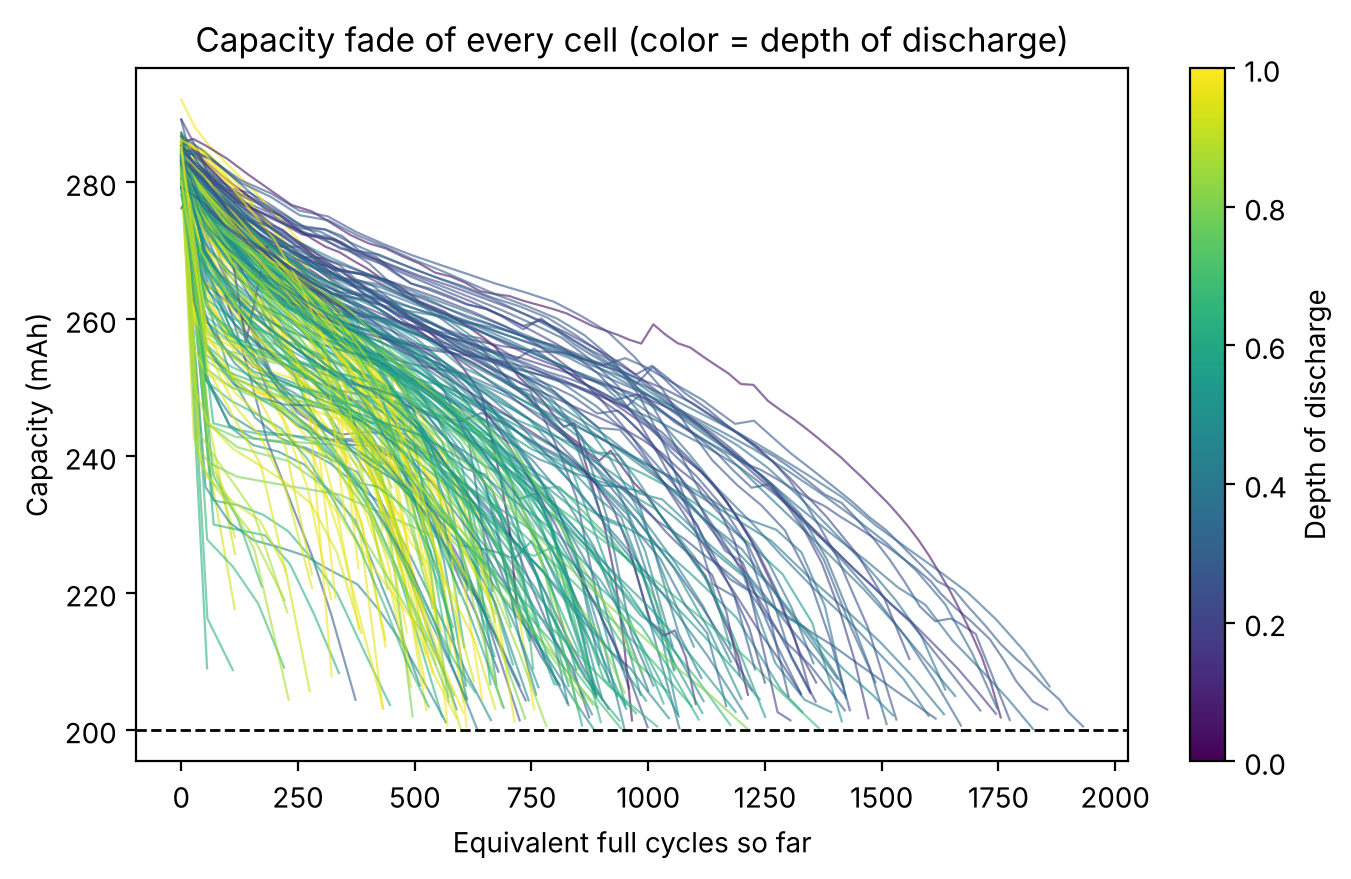

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for cell, df in steps.groupby('cell'):
    ax.plot(df['efc_so_far'], df['capacity'] * 1000, color=plt.cm.viridis(min(df['dod'].iloc[0], 1.0)), lw=0.8, alpha=0.6)
ax.axhline(EOL_AH * 1000, color='k', ls='--', lw=1)
ax.set_xlabel('Equivalent full cycles so far')
ax.set_ylabel('Capacity (mAh)')
ax.set_title('Capacity fade of every cell (color = depth of discharge)')
fig.colorbar(plt.cm.ScalarMappable(cmap=plt.cm.viridis), ax=ax, label='Depth of discharge')
fig.savefig('figures/capacity_fade.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Sequences
Each cell is one sequence of weekly tests. Every step has seven inputs: capacity, EFC so far, capacity lost, fade slope, and the three usage conditions. The target at every step is log(RUL), with RUL floored at 10 EFC so that the last test before the end of life does not dominate the loss. Sequences are padded to a common length and a mask marks the real steps.

In [4]:
COND = ['c_chg', 'c_dis', 'dod']
FEATURES = ['capacity', 'efc_so_far', 'cap_lost', 'slope'] + COND
RUL_FLOOR = 10.0

cell_ids = steps['cell'].drop_duplicates().values
cell_group = steps.drop_duplicates('cell').set_index('cell')['group'].loc[cell_ids].values
T_MAX = steps.groupby('cell').size().max()

X = np.zeros((len(cell_ids), T_MAX, len(FEATURES)), dtype=np.float32)   # inputs
RUL = np.zeros((len(cell_ids), T_MAX), dtype=np.float32)                # true RUL in EFC
M = np.zeros((len(cell_ids), T_MAX), dtype=bool)                        # True where a real step exists
row_index = np.full((len(cell_ids), T_MAX), -1)                         # row of `steps` for each step
for i, cell in enumerate(cell_ids):
    df = steps[steps['cell'] == cell]
    t = len(df)
    X[i, :t], RUL[i, :t], M[i, :t], row_index[i, :t] = df[FEATURES].values, df['rul_efc'].values, True, df.index.values
Y = np.log(np.maximum(RUL, RUL_FLOOR))                                  # training target

cv = GroupKFold(n_splits=5)
FOLDS = list(cv.split(cell_ids, groups=cell_group))                     # folds never split an experimental group
print('Input tensor:', X.shape, '(cells, steps, features)')

Input tensor: (245, 59, 7) (cells, steps, features)


## 4. Model
- **LSTM**: reads the sequence step by step. Its state at step *k* depends only on tests up to *k*.
- **Attention** (optional): at each step, a self-attention layer weighs all earlier LSTM states and returns a summary of the history. A causal mask stops it from looking at future tests.
- **Head**: a two-layer network with the Swish activation, `swish(x) = x * sigmoid(x)`, maps the state to log(RUL). Swish is smooth and lets small negative values through, unlike ReLU.

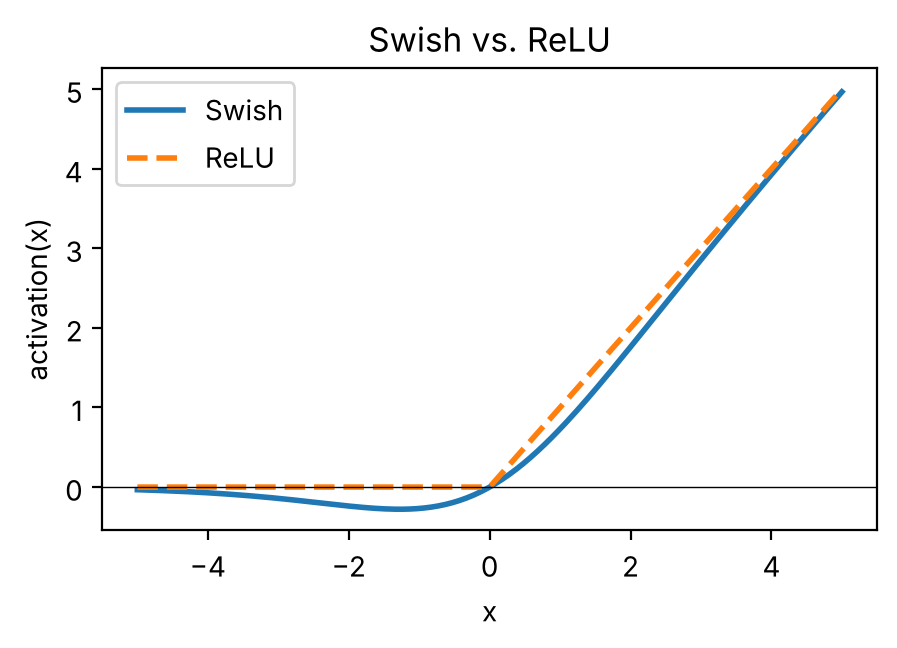

RULNet(
  (lstm): LSTM(7, 32, batch_first=True)
  (attention): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
  )
  (head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): SiLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [5]:
class RULNet(nn.Module):
    def __init__(self, n_features, hidden=32, attention=True, activation='swish'):
        super().__init__()
        act = nn.SiLU() if activation == 'swish' else nn.ReLU()            # nn.SiLU is Swish
        self.lstm = nn.LSTM(n_features, hidden, batch_first=True)
        self.attention = nn.MultiheadAttention(hidden, num_heads=1, batch_first=True) if attention else None
        self.head = nn.Sequential(nn.Linear(hidden * (2 if attention else 1), 32), act, nn.Linear(32, 1))

    def forward(self, x, padding, return_weights=False):
        states, _ = self.lstm(x)                                           # (cells, steps, hidden)
        weights = None
        if self.attention is not None:
            t = x.shape[1]
            future = torch.triu(torch.ones(t, t, dtype=torch.bool, device=x.device), diagonal=1)
            context, weights = self.attention(states, states, states, attn_mask=future, key_padding_mask=padding)
            states = torch.cat([states, context], dim=-1)                  # current state + attended history
        out = self.head(states).squeeze(-1)                                # log(RUL) at every step
        return (out, weights) if return_weights else out

x = torch.linspace(-5, 5, 200)
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(x, nn.SiLU()(x), lw=2, label='Swish')
ax.plot(x, nn.ReLU()(x), '--', lw=2, label='ReLU')
ax.axhline(0, color='k', lw=0.5)
ax.set_xlabel('x'); ax.set_ylabel('activation(x)'); ax.set_title('Swish vs. ReLU')
ax.legend()
fig.savefig('figures/swish_vs_relu.png', dpi=150, bbox_inches='tight')
plt.show()
print(RULNet(len(FEATURES)))

## 5. Training
- **Unseen conditions.** Five-fold `GroupKFold` by experimental group: every prediction is for a group the model was not trained on.
- **Early stopping.** Training longer made the models worse on unseen groups, so 20% of the training groups are held out, and training stops at the epoch with the lowest error on them.
- **Details.** Mini-batches of 32 cells, Adam, mean squared error of log(RUL) over real steps, inputs standardized with training statistics, output bias initialized to the mean target.

In [6]:
BATCH, LR, MAX_EPOCHS, PATIENCE, CHECK_EVERY = 32, 3e-3, 120, 20, 2

def train_fold(train, test, attention, activation, seed):
    torch.manual_seed(seed)
    groups = np.unique(cell_group[train])
    np.random.RandomState(seed).shuffle(groups)
    held_out = np.isin(cell_group[train], groups[:len(groups) // 5])      # validation groups for early stopping
    val, fit = train[held_out], train[~held_out]

    mean = X[fit][M[fit]].mean(axis=0)
    std = X[fit][M[fit]].std(axis=0) + 1e-8
    scale = lambda a: torch.tensor((a - mean) / std)
    x, y, m = scale(X[fit]), torch.tensor(Y[fit]), torch.tensor(M[fit])
    x_val, pad_val = scale(X[val]), torch.tensor(~M[val])

    model = RULNet(len(FEATURES), attention=attention, activation=activation)
    with torch.no_grad():
        model.head[-1].bias.fill_(float(Y[fit][M[fit]].mean()))
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)

    best_error, best_epoch, best_state, history = np.inf, 0, None, []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        order = torch.randperm(len(x))
        for start in range(0, len(x), BATCH):
            b = order[start:start + BATCH]
            optimizer.zero_grad()
            loss = ((model(x[b], ~m[b]) - y[b])[m[b]] ** 2).mean()         # padded steps are excluded
            loss.backward()
            optimizer.step()
        if epoch % CHECK_EVERY == 0:
            model.eval()
            with torch.no_grad():
                pred_val = np.exp(model(x_val, pad_val).numpy())
            error = np.abs(pred_val - RUL[val])[M[val]].mean()             # validation MAE in EFC
            history.append((epoch, error))
            if error < best_error:
                best_error, best_epoch = error, epoch
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
            elif epoch - best_epoch >= PATIENCE:
                break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        pred_test = np.exp(model(scale(X[test]), torch.tensor(~M[test])).numpy())
    return pred_test, {'model': model, 'scale': scale, 'history': history, 'best_epoch': best_epoch, 'test': test}

def cross_validate(attention, activation, seed):
    pred, first_fold = np.zeros_like(RUL), None
    for train, test in FOLDS:
        pred[test], info = train_fold(train, test, attention, activation, seed)
        first_fold = first_fold or info
    return pred[M], first_fold                         # predictions for every real step, in EFC

DEEP_MODELS = {
    'LSTM + Swish':             dict(attention=False, activation='swish'),
    'LSTM + attention + ReLU':  dict(attention=True,  activation='relu'),
    'LSTM + attention + Swish': dict(attention=True,  activation='swish'),
}
deep_pred, deep_info = {}, {}
for name, options in DEEP_MODELS.items():
    runs = [cross_validate(seed=s, **options) for s in range(N_SEEDS)]
    deep_pred[name] = [p for p, _ in runs]
    deep_info[name] = runs[0][1]
    print(name, 'done')

true_rul = RUL[M]
step_rows = row_index[M]
life_frac = steps['life_frac'].values[step_rows]

LSTM + Swish done


LSTM + attention + ReLU done


LSTM + attention + Swish done


Validation error during training for the first fold. The dot marks the epoch that early stopping kept.

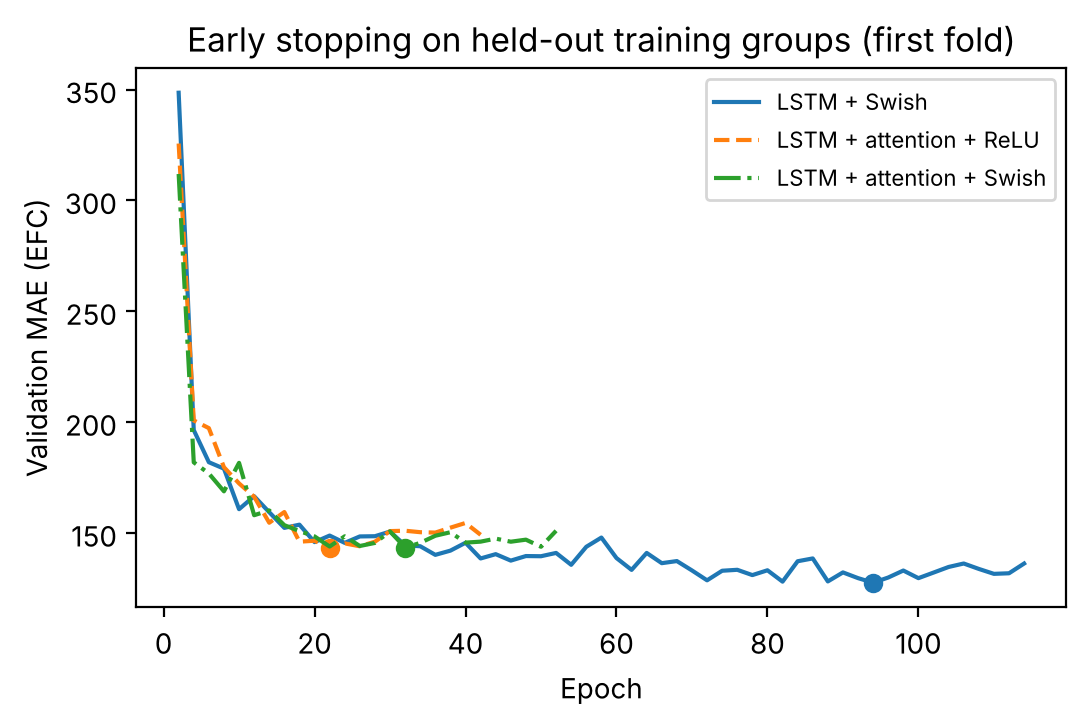

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for (name, info), style in zip(deep_info.items(), ['-', '--', '-.']):
    epochs, errors = zip(*info['history'])
    line, = ax.plot(epochs, errors, style, label=name)
    ax.plot(info['best_epoch'], min(errors), 'o', color=line.get_color())
ax.set_xlabel('Epoch'); ax.set_ylabel('Validation MAE (EFC)')
ax.set_title('Early stopping on held-out training groups (first fold)')
ax.legend(fontsize=8)
fig.savefig('figures/early_stopping.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Baselines
Two random forests, evaluated on the same folds:

- **Conditions only**: predicts total lifetime from the three usage conditions and subtracts the cycles already used. It never sees the cell's capacity.
- **Fade features**: gets the same seven inputs as the deep models, one test at a time, with no memory of earlier tests.

In [8]:
first_step = steps[steps['step'] == 0]
rf_cond, rf_fade = np.zeros(len(steps)), np.zeros(len(steps))
for train, test in FOLDS:
    tr_cells = set(cell_ids[train])
    tr = steps['cell'].isin(tr_cells).values
    te = steps['cell'].isin(set(cell_ids[test])).values

    total = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=0, n_jobs=-1)
    f_tr = first_step[first_step['cell'].isin(tr_cells)]
    total.fit(f_tr[COND].values, np.log(f_tr['efc_total'].values))
    rf_cond[te] = np.maximum(np.exp(total.predict(steps.loc[te, COND].values)) - steps.loc[te, 'efc_so_far'].values, 1.0)

    fade = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=0, n_jobs=-1)
    fade.fit(steps.loc[tr, FEATURES].values, np.log(steps.loc[tr, 'rul_efc'].values))
    rf_fade[te] = np.exp(fade.predict(steps.loc[te, FEATURES].values))

rf_cond, rf_fade = rf_cond[step_rows], rf_fade[step_rows]      # same order as the deep-model predictions

## 7. Results
Errors are in equivalent full cycles (EFC). For the deep models, *MAE* is the mean over the random initializations, *MAE std* is the spread across them, and *Ensemble MAE* is the error after averaging their predictions.

In [9]:
def errors(pred):
    err = np.abs(pred - true_rul)
    return {'MAE (EFC)': err.mean(), 'RMSE (EFC)': np.sqrt((err ** 2).mean()),
            'Median error (%)': 100 * np.median(err / true_rul)}

rows = [{'model': 'Random forest, conditions only', **errors(rf_cond)},
        {'model': 'Random forest, fade features', **errors(rf_fade)}]
ensemble = {}
for name, preds in deep_pred.items():
    per_seed = pd.DataFrame([errors(p) for p in preds])
    ensemble[name] = np.mean(preds, axis=0)
    rows.append({'model': name, **per_seed.mean().to_dict(), 'MAE std': per_seed['MAE (EFC)'].std(),
                 'Ensemble MAE (EFC)': errors(ensemble[name])['MAE (EFC)']})
results = pd.DataFrame(rows).round(1)
results.to_csv('figures/results.csv', index=False)
results

,model,MAE (EFC),RMSE (EFC),Median error (%),MAE std,Ensemble MAE (EFC)
0,"Random forest, conditions only",203.0,270.6,40.1,NaN,NaN
1,"Random forest, fade features",137.7,211.8,22.7,NaN,NaN
2,LSTM + Swish,149.4,227.4,25.5,3.7,142.6
3,LSTM + attention + ReLU,147.8,225.8,24.8,5.4,140.7
4,LSTM + attention + Swish,147.4,220.8,25.5,4.6,140.4


The same errors on the tests that follow the first 30 cycles. The usage conditions are computed from those cycles, so only these tests could be predicted if the conditions had to be measured on the cell itself (report Section IV-B).

In [10]:
RATED_AH = 0.25
# Cycles before each test, estimated from the EFC used and the discharge of the first cycles.
# Later cycles discharge less, so this is a lower bound on the true count.
first_cycle_ah = steps['dod'] * steps.groupby('cell')['capacity'].transform('first')
cycles_before = (steps['efc_so_far'] * RATED_AH / first_cycle_ah).values[step_rows]
after_30 = cycles_before >= 30
print(f'{after_30.sum()} of {len(after_30)} tests follow at least 30 cycles')

for name, pred in {'RF, conditions only': rf_cond, 'RF, fade features': rf_fade, **deep_pred}.items():
    pred = np.asarray(pred)
    if pred.ndim == 2:                                            # deep models: five runs
        mae = np.mean([np.abs(run - true_rul)[after_30].mean() for run in pred])
        ens = np.abs(pred.mean(axis=0) - true_rul)[after_30].mean()
        print(f'{name:28s} MAE {mae:6.1f} EFC   ensemble {ens:6.1f} EFC')
    else:
        print(f'{name:28s} MAE {np.abs(pred - true_rul)[after_30].mean():6.1f} EFC')


3671 of 3956 tests follow at least 30 cycles
RF, conditions only          MAE  204.3 EFC
RF, fade features            MAE  133.9 EFC
LSTM + Swish                 MAE  145.3 EFC   ensemble  138.3 EFC
LSTM + attention + ReLU      MAE  143.1 EFC   ensemble  135.9 EFC
LSTM + attention + Swish     MAE  142.9 EFC   ensemble  135.8 EFC


How the error changes as more of the cell's life has been observed (deep models: ensemble predictions).

The gray line is an **oracle** that is told the true mean life of each held-out group by the group's other cells, which no real model can know (section 10).

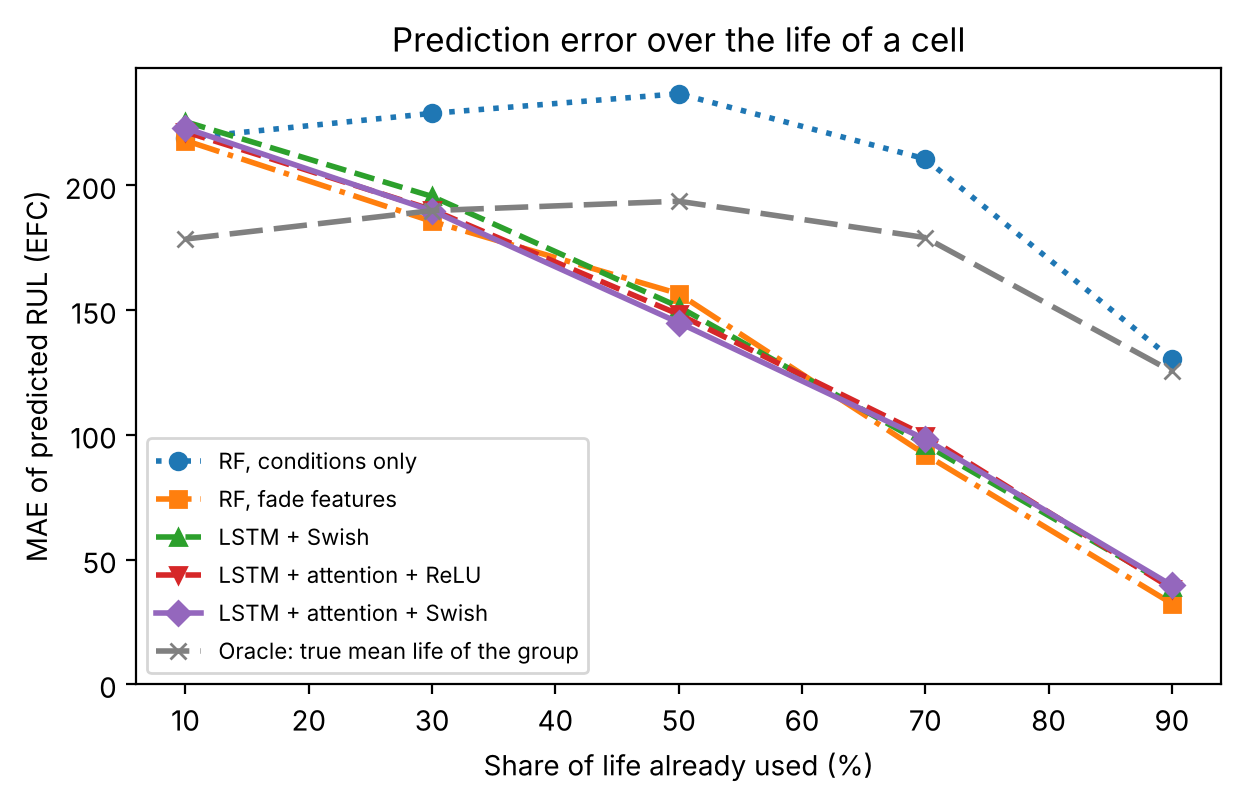

,"RF, conditions only","RF, fade features",LSTM + Swish,LSTM + attention + ReLU,LSTM + attention + Swish,Oracle: true mean life of the group
Share of life used,,,,,,
0-20%,219.0,218.0,226.0,221.0,223.0,179.0
20-40%,229.0,186.0,196.0,190.0,190.0,190.0
40-60%,237.0,157.0,151.0,148.0,145.0,194.0
60-80%,211.0,92.0,96.0,100.0,98.0,179.0
80-100%,130.0,32.0,39.0,38.0,40.0,125.0


In [11]:
compared = {'RF, conditions only': rf_cond, 'RF, fade features': rf_fade, **ensemble}
bins = np.linspace(0, 1, 6)
centers = (bins[:-1] + bins[1:]) / 2
which = np.clip(np.digitize(life_frac, bins) - 1, 0, len(centers) - 1)

# Oracle: told the true mean life of the held-out group by the group's other cells (impossible in practice).
# Its error is what remains from the spread between cells cycled the same way (section 10).
cells_tab = steps.drop_duplicates('cell').set_index('cell')
g_sum = cells_tab.groupby('group')['efc_total'].transform('sum')
g_n = cells_tab.groupby('group')['efc_total'].transform('count')
sibling_life = ((g_sum - cells_tab['efc_total']) / (g_n - 1)).where(g_n > 1)
oracle = np.maximum(sibling_life.loc[steps['cell'].values[step_rows]].values - steps['efc_so_far'].values[step_rows], 1.0)
compared['Oracle: true mean life of the group'] = oracle       # NaN for the one group with a single cell

by_stage = pd.DataFrame({name: [np.nanmean(np.abs(pred - true_rul)[which == b]) for b in range(len(centers))]
                         for name, pred in compared.items()},
                        index=[f'{int(lo * 100)}-{int(hi * 100)}%' for lo, hi in zip(bins[:-1], bins[1:])])
by_stage.index.name = 'Share of life used'
by_stage.round(0).to_csv('figures/error_by_stage.csv')

fig, ax = plt.subplots(figsize=(7, 4))
styles = [':', '-.', '--', '--', '-', (0, (6, 2))]
for name, style, marker in zip(compared, styles, ['o', 's', '^', 'v', 'D', 'x']):
    ax.plot(centers * 100, by_stage[name], linestyle=style, marker=marker, lw=2, label=name,
            color='gray' if name.startswith('Oracle') else None)
ax.set_xlabel('Share of life already used (%)')
ax.set_ylabel('MAE of predicted RUL (EFC)')
ax.set_title('Prediction error over the life of a cell')
ax.set_ylim(bottom=0)
ax.legend(fontsize=8)
fig.savefig('figures/error_over_life.png', dpi=150, bbox_inches='tight')
plt.show()
by_stage.round(0)

Predicted against true RUL for the LSTM + attention + Swish ensemble, on held-out groups.

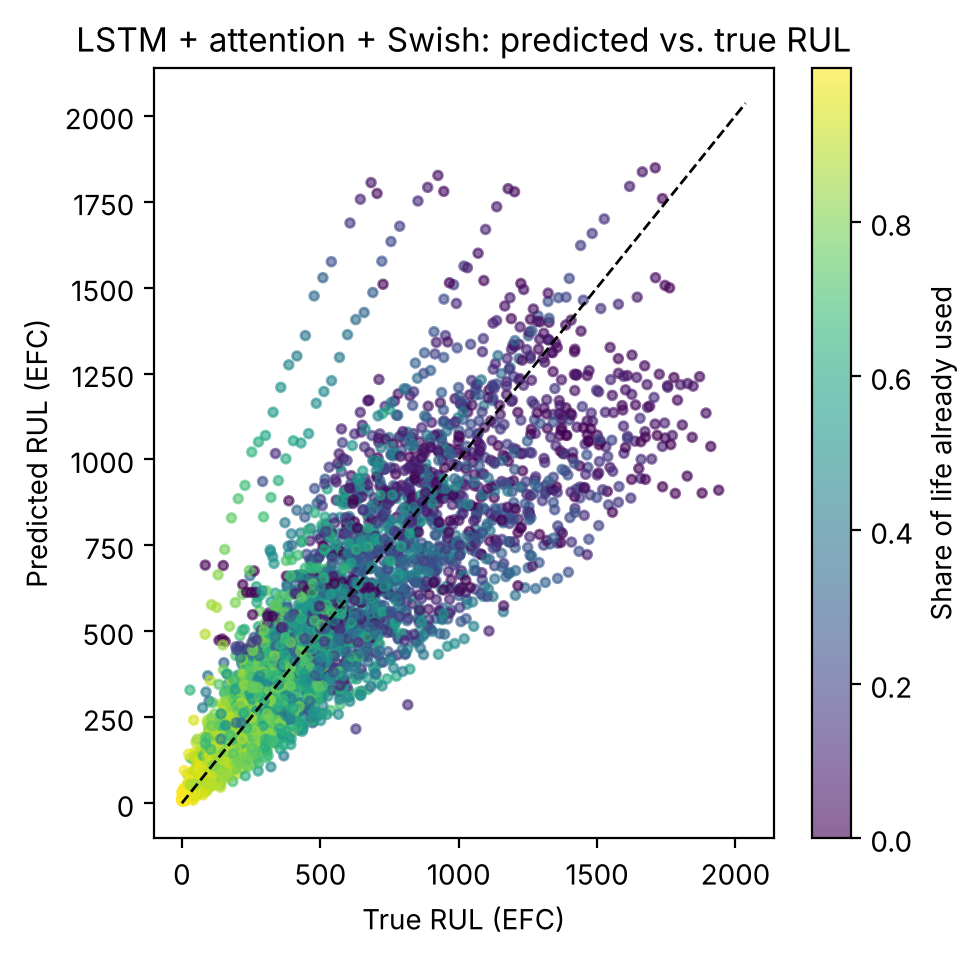

In [12]:
best = ensemble['LSTM + attention + Swish']
fig, ax = plt.subplots(figsize=(5, 5))
points = ax.scatter(true_rul, best, c=life_frac, cmap='viridis', s=10, alpha=0.6)
lim = [0, max(true_rul.max(), best.max()) * 1.05]
ax.plot(lim, lim, 'k--', lw=1)
ax.set_xlabel('True RUL (EFC)'); ax.set_ylabel('Predicted RUL (EFC)')
ax.set_title('LSTM + attention + Swish: predicted vs. true RUL')
fig.colorbar(points, ax=ax, label='Share of life already used')
fig.savefig('figures/predicted_vs_true.png', dpi=150, bbox_inches='tight')
plt.show()

RUL over the life of four held-out cells, picked across the range of lifetimes.

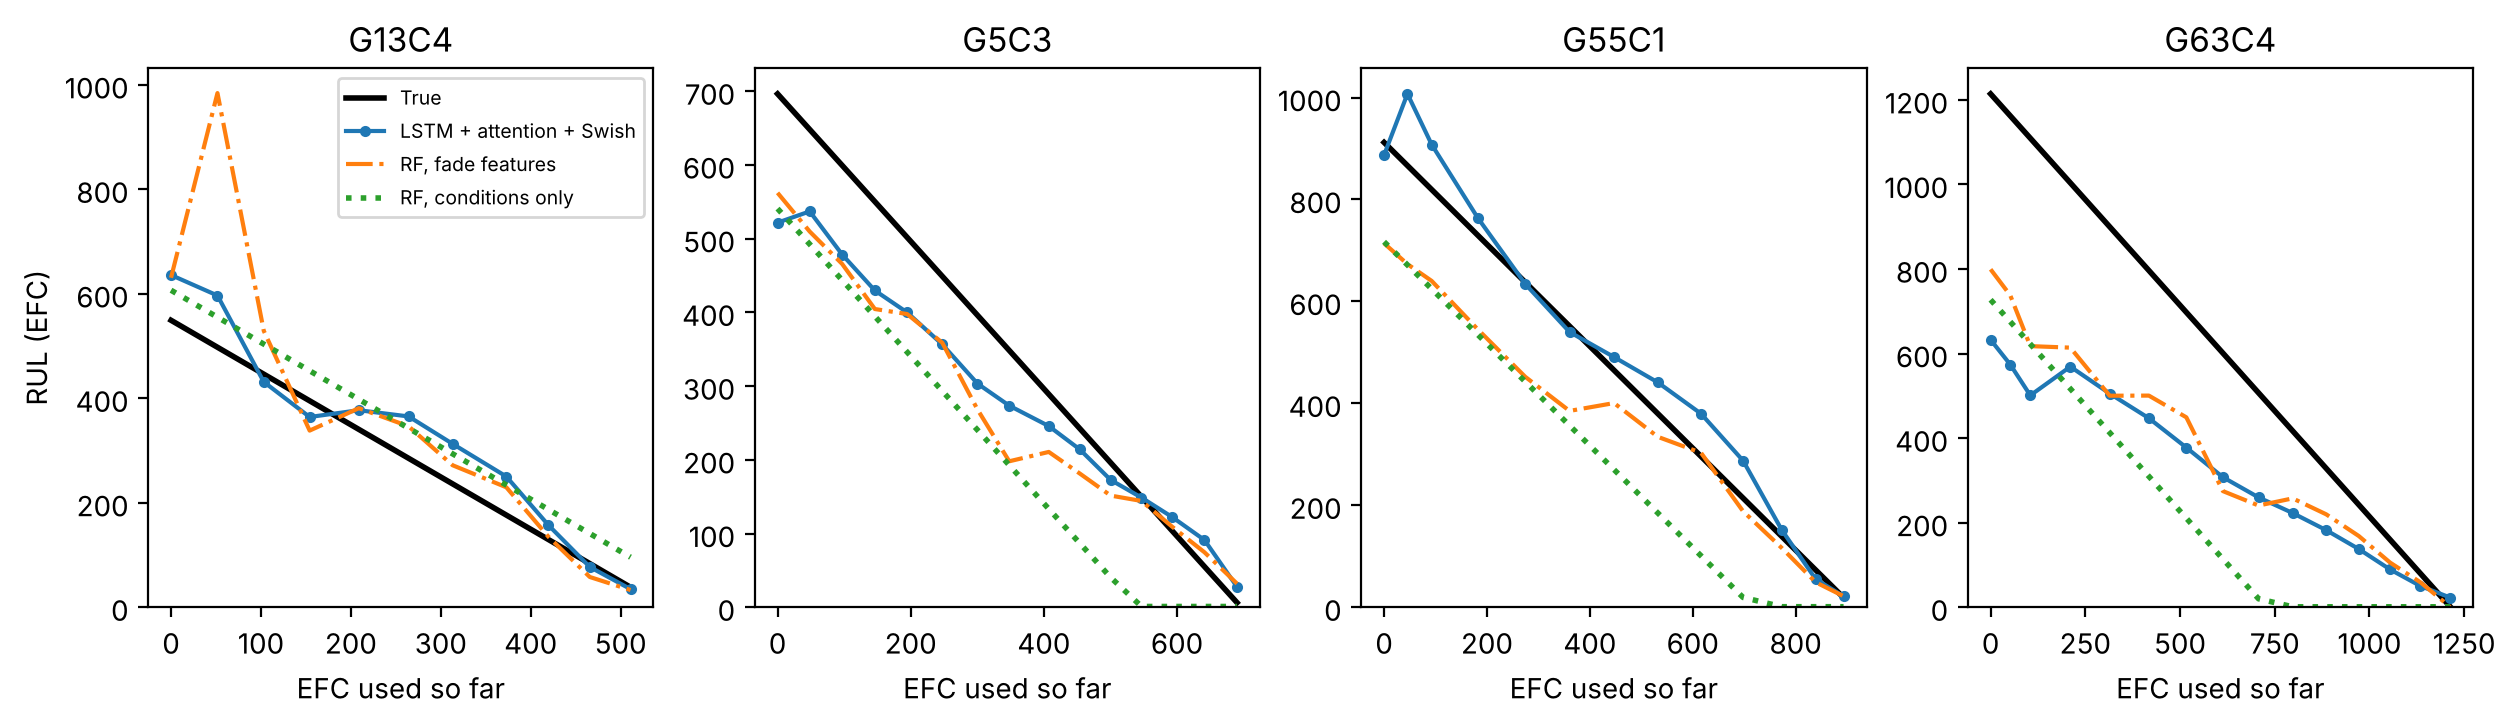

In [13]:
cell_of_step = steps['cell'].values[step_rows]
used = steps['efc_so_far'].values[step_rows]
lifetimes = steps.drop_duplicates('cell').sort_values('efc_total')
examples = lifetimes['cell'].values[np.linspace(0, len(lifetimes) - 1, 6).astype(int)[1:5]]

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, cell in zip(axes, examples):
    sel = cell_of_step == cell
    ax.plot(used[sel], true_rul[sel], 'k-', lw=2, label='True')
    ax.plot(used[sel], best[sel], '-o', ms=3, label='LSTM + attention + Swish')
    ax.plot(used[sel], rf_fade[sel], '-.', lw=1.5, label='RF, fade features')
    ax.plot(used[sel], rf_cond[sel], ':', lw=2, label='RF, conditions only')
    ax.set_title(cell)
    ax.set_xlabel('EFC used so far')
    ax.set_ylim(bottom=0)
axes[0].set_ylabel('RUL (EFC)')
axes[0].legend(fontsize=7)
fig.savefig('figures/example_cells.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. How many weekly tests are needed?
Error against the number of weekly tests observed so far. To compare cells with different lifetimes, the error is expressed as a share of each cell's total life. The table also shows how many cells are still alive at each point, since short-lived cells drop out.

Median error stays at or below 20% of total life from 2 tests
Median error stays at or below 15% of total life from 6 tests
Median error stays at or below 10% of total life from 8 tests


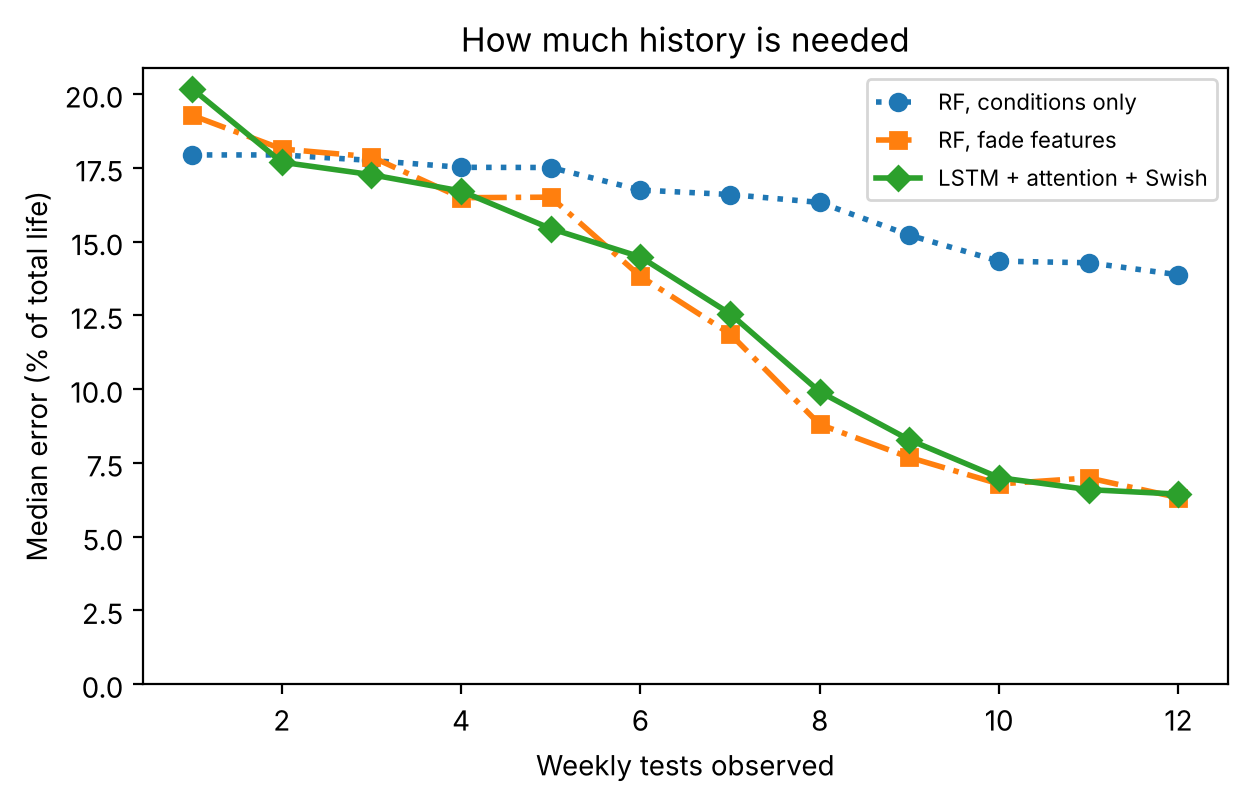

,Cells still alive,"RF, conditions only","RF, fade features",LSTM + attention + Swish
Weekly tests observed,,,,
1,245,17.9,19.3,20.2
2,245,17.9,18.1,17.7
3,244,17.8,17.9,17.3
4,240,17.5,16.5,16.7
5,239,17.5,16.5,15.4
6,234,16.7,13.8,14.5
7,231,16.6,11.9,12.6
8,226,16.3,8.8,9.9
9,217,15.2,7.7,8.3


In [14]:
total_life = steps['efc_total'].values[step_rows]
n_tests = steps['step'].values[step_rows] + 1                    # tests seen so far, including the first one
relative = {name: np.abs(pred - true_rul) / total_life * 100 for name, pred in
            {'RF, conditions only': rf_cond, 'RF, fade features': rf_fade, 'LSTM + attention + Swish': best}.items()}

MAX_TESTS = 12
by_tests = pd.DataFrame({name: [np.median(err[n_tests == k]) for k in range(1, MAX_TESTS + 1)] for name, err in relative.items()},
                        index=pd.Index(range(1, MAX_TESTS + 1), name='Weekly tests observed'))
by_tests.insert(0, 'Cells still alive', [(n_tests == k).sum() for k in range(1, MAX_TESTS + 1)])
by_tests.round(1).to_csv('figures/error_by_tests.csv')

# Smallest number of tests from which the deep model stays under each error level
lstm = by_tests['LSTM + attention + Swish'].values
for level in [20, 15, 10]:
    ok = [k for k in range(1, MAX_TESTS + 1) if (lstm[k - 1:] <= level).all()]
    print(f'Median error stays at or below {level}% of total life from', f'{ok[0]} tests' if ok else f'more than {MAX_TESTS} tests')

fig, ax = plt.subplots(figsize=(7, 4))
for name, style, marker in zip(relative, [':', '-.', '-'], ['o', 's', 'D']):
    ax.plot(by_tests.index, by_tests[name], style, marker=marker, lw=2, label=name)
ax.set_xlabel('Weekly tests observed')
ax.set_ylabel('Median error (% of total life)')
ax.set_title('How much history is needed')
ax.set_ylim(bottom=0)
ax.legend(fontsize=8)
fig.savefig('figures/error_by_tests.png', dpi=150, bbox_inches='tight')
plt.show()
by_tests.round(1)

## 9. Prediction intervals
A single number hides how uncertain a prediction is, and early in a cell's life the error is large. Two ways to give a range are compared:

- **Spread of the five training runs** from section 5: the lowest and highest of the five predictions.
- **Quantile LSTM**: the same network with three outputs, trained with the pinball loss to predict the 10th, 50th and 90th percentiles of log(RUL). Its 10-90% range should contain the true RUL 80% of the time. Five runs are trained and their percentiles averaged.
- **Conformal quantile LSTM**: the quantile interval widened in log space by an offset fitted on out-of-fold errors from the *other* folds, one offset per predicted stage of life (conformalized quantile regression). The predicted stage uses the predicted RUL, so it is known at prediction time.

*Coverage* is the share of held-out tests whose true RUL falls inside the range.

In [15]:
QUANTILES = [0.1, 0.5, 0.9]                        # lower bound, median, upper bound


class QuantileRULNet(RULNet):
    # Same network as RULNet, but the last layer outputs three values per step:
    # the 10th, 50th and 90th percentile of log(RUL).
    def __init__(self, n_features, **kwargs):
        super().__init__(n_features, **kwargs)
        self.head[-1] = nn.Linear(32, len(QUANTILES))

    def forward(self, x, padding):
        states, _ = self.lstm(x)
        if self.attention is not None:
            t = x.shape[1]
            future = torch.triu(torch.ones(t, t, dtype=torch.bool, device=x.device), diagonal=1)
            context, _ = self.attention(states, states, states, attn_mask=future, key_padding_mask=padding)
            states = torch.cat([states, context], dim=-1)
        return self.head(states)                     # (cells, steps, 3)


def pinball_loss(pred, target):
    # Quantile (pinball) loss: under-predicting the 90th percentile costs 9 times more than over-predicting it
    q = torch.tensor(QUANTILES)
    diff = target.unsqueeze(-1) - pred
    return torch.maximum(q * diff, (q - 1) * diff).mean()


def train_quantile_fold(train, test, seed):
    torch.manual_seed(seed)
    groups = np.unique(cell_group[train])
    np.random.RandomState(seed).shuffle(groups)
    held_out = np.isin(cell_group[train], groups[:len(groups) // 5])
    val, fit = train[held_out], train[~held_out]

    mean = X[fit][M[fit]].mean(axis=0)
    std = X[fit][M[fit]].std(axis=0) + 1e-8
    scale = lambda a: torch.tensor((a - mean) / std)
    x, y, m = scale(X[fit]), torch.tensor(Y[fit]), torch.tensor(M[fit])
    x_val, y_val, m_val = scale(X[val]), torch.tensor(Y[val]), torch.tensor(M[val])

    model = QuantileRULNet(len(FEATURES), attention=True, activation='swish')
    with torch.no_grad():
        model.head[-1].bias.copy_(torch.tensor(np.quantile(Y[fit][M[fit]], QUANTILES), dtype=torch.float32))
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)

    best_loss, best_epoch, best_state = np.inf, 0, None
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        order = torch.randperm(len(x))
        for start in range(0, len(x), BATCH):
            b = order[start:start + BATCH]
            optimizer.zero_grad()
            loss = pinball_loss(model(x[b], ~m[b])[m[b]], y[b][m[b]])
            loss.backward()
            optimizer.step()
        if epoch % CHECK_EVERY == 0:
            model.eval()
            with torch.no_grad():
                val_loss = pinball_loss(model(x_val, ~m_val)[m_val], y_val[m_val]).item()
            if val_loss < best_loss:
                best_loss, best_epoch = val_loss, epoch
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
            elif epoch - best_epoch >= PATIENCE:
                break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        pred = model(scale(X[test]), torch.tensor(~M[test])).numpy()
    return np.sort(pred, axis=-1), {'model': model, 'scale': scale}   # sorting stops the quantiles from crossing


quantile_runs = []
for seed in range(N_SEEDS):
    pred = np.zeros(RUL.shape + (len(QUANTILES),), dtype=np.float32)
    for train, test in FOLDS:
        pred[test], _ = train_quantile_fold(train, test, seed)
    quantile_runs.append(np.exp(pred[M]))                           # (steps, 3) in EFC
q_low, q_mid, q_high = np.mean(quantile_runs, axis=0).T             # average the five runs
print('Quantile model done')

Quantile model done


In [16]:
runs = np.array(deep_pred['LSTM + attention + Swish'])            # (five runs, steps)

# Conformal calibration: scores > 0 mean the true RUL fell outside the raw interval (in log space)
fold_of_cell = np.zeros(len(cell_ids), dtype=int)
for f, (_, test) in enumerate(FOLDS):
    fold_of_cell[test] = f
fold_of_step = np.repeat(fold_of_cell[:, None], M.shape[1], axis=1)[M]
y_log, lo_log, hi_log = np.log(np.maximum(true_rul, RUL_FLOOR)), np.log(q_low), np.log(q_high)
score = np.maximum(lo_log - y_log, y_log - hi_log)
used = steps['efc_so_far'].values[step_rows]
pred_stage = np.clip((used / (used + q_mid) * 5).astype(int), 0, 4)  # predicted share of life used, in fifths

def conformal_offset(s, alpha=0.2):
    n = len(s)
    return np.quantile(s, min(1.0, np.ceil((n + 1) * (1 - alpha)) / n), method='higher')

c_low, c_high = np.zeros_like(q_low), np.zeros_like(q_high)
for f in range(len(FOLDS)):
    test_f, cal = fold_of_step == f, fold_of_step != f                # calibrate on the other folds only
    for b in range(5):
        t_b, c_b = test_f & (pred_stage == b), cal & (pred_stage == b)
        off = conformal_offset(score[c_b] if c_b.sum() >= 30 else score[cal])
        c_low[t_b], c_high[t_b] = np.exp(lo_log[t_b] - off), np.exp(hi_log[t_b] + off)

intervals = {'Spread of five runs': (runs.min(axis=0), runs.max(axis=0)),
             'Quantile LSTM, 10-90%': (q_low, q_high),
             'Conformal quantile LSTM, 10-90%': (c_low, c_high)}
stage_labels = [f'{int(lo * 100)}-{int(hi * 100)}%' for lo, hi in zip(bins[:-1], bins[1:])]

rows = []
for name, (lo, hi) in intervals.items():
    inside = (true_rul >= lo) & (true_rul <= hi)
    width = hi - lo
    groups = [('All', np.ones(len(inside), dtype=bool))] + [(label, which == b) for b, label in enumerate(stage_labels)]
    for label, sel in groups:
        rows.append({'Interval': name, 'Share of life used': label,
                     'Coverage (%)': 100 * inside[sel].mean(), 'Median width (EFC)': np.median(width[sel])})
coverage = pd.DataFrame(rows).round(1)
coverage.to_csv('figures/interval_coverage.csv', index=False)
print('MAE of the quantile median:', round(np.abs(q_mid - true_rul).mean(), 1), 'EFC')
inside_c = (true_rul >= c_low) & (true_rul <= c_high)
per_group = pd.Series(inside_c).groupby(steps['group'].values[step_rows]).mean()
print(f'Conformal coverage per group: median {100 * per_group.median():.0f}%, '
      f'below 50% in {(per_group < 0.5).sum()} of {len(per_group)} groups')
coverage.pivot(index='Share of life used', columns='Interval',
               values=['Coverage (%)', 'Median width (EFC)']).loc[['All'] + stage_labels]

MAE of the quantile median: 141.5 EFC
Conformal coverage per group: median 86%, below 50% in 5 of 63 groups


Coverage (%)                        \
Interval           Conformal quantile LSTM, 10-90% Quantile LSTM, 10-90%   
Share of life used                                                         
All                                           78.7                  73.2   
0-20%                                         79.7                  76.4   
20-40%                                        78.4                  74.4   
40-60%                                        78.6                  72.6   
60-80%                                        80.8                  73.5   
80-100%                                       76.1                  68.8   

                                                    Median width (EFC)  \
Interval           Spread of five runs Conformal quantile LSTM, 10-90%   
Share of life used                                                       
All                               32.6                      419.600006   
0-20%                             27.6                      703.000000   
20-40%                            31.3                      554.799988   
40-60%                            34.6                      441.500000   
60-80%                            33.6                      306.100006   
80-100%                           37.1                      113.500000   

                                                              
Interval           Quantile LSTM, 10-90% Spread of five runs  
Share of life used                                            
All                           361.899994          106.199997  
0-20%                         664.900024          151.100006  
20-40%                        493.200012          151.500000  
40-60%                        370.500000          133.699997  
60-80%                        253.199997           97.800003  
80-100%                        88.199997           36.799999

The 10-90% range of the quantile LSTM for the same four held-out cells as in section 7.

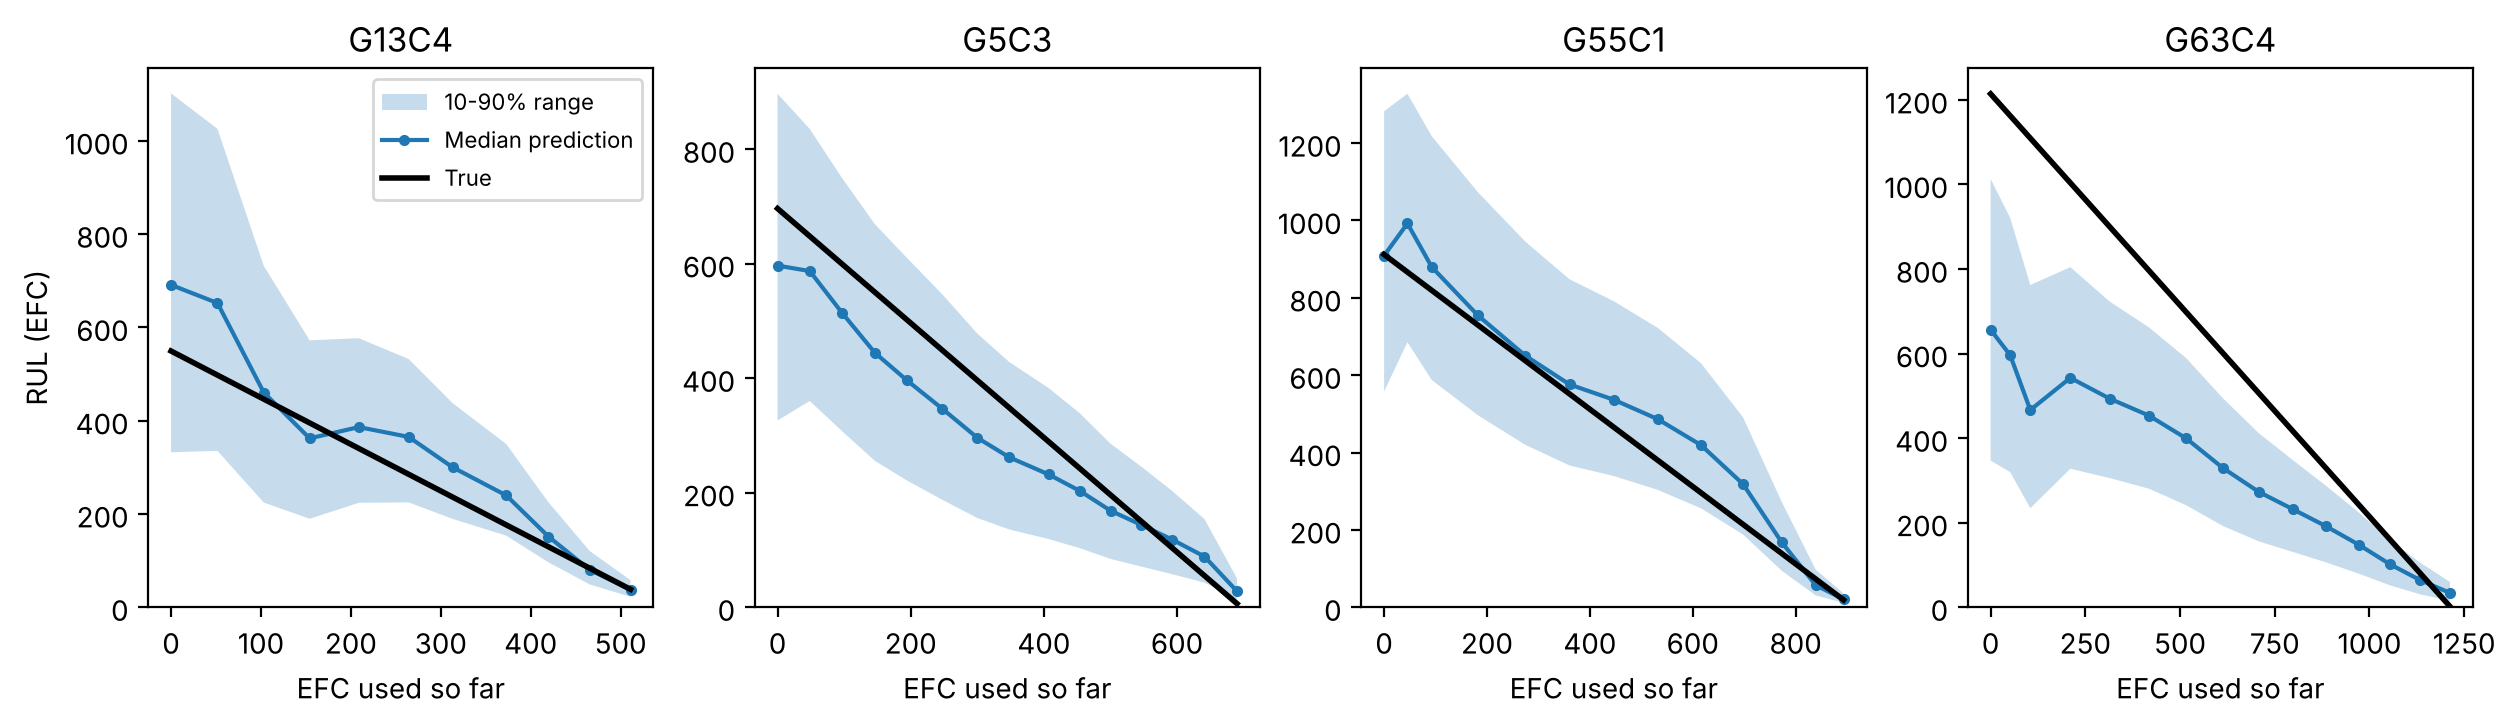

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, cell in zip(axes, examples):
    sel = cell_of_step == cell
    ax.fill_between(used[sel], q_low[sel], q_high[sel], alpha=0.25, label='10-90% range')
    ax.plot(used[sel], q_mid[sel], '-o', ms=3, label='Median prediction')
    ax.plot(used[sel], true_rul[sel], 'k-', lw=2, label='True')
    ax.set_title(cell)
    ax.set_xlabel('EFC used so far')
    ax.set_ylim(bottom=0)
axes[0].set_ylabel('RUL (EFC)')
axes[0].legend(fontsize=8)
fig.savefig('figures/prediction_intervals.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Where the error comes from
The oracle of section 7 knows each held-out group's true mean life, so its error is what remains from the spread between cells cycled the same way. The second part asks whether held-out groups whose conditions lie outside the training range, or far from the nearest training condition, are predicted worse (relative error = error / total life of the cell).

In [18]:
from scipy.stats import spearmanr

ok = ~np.isnan(oracle)
err = {name: np.abs(compared[name] - true_rul) for name in
       ['RF, conditions only', 'RF, fade features', 'LSTM + attention + Swish', 'Oracle: true mean life of the group']}
sources = pd.DataFrame({name: [e[ok].mean()] + [e[ok & (which == b)].mean() for b in range(5)] for name, e in err.items()},
                       index=['All'] + stage_labels).T.round(1)
sources.to_csv('figures/error_sources.csv')
print(f'MAE (EFC) on the {ok.sum()} tests whose group has another cell:')
display(sources)

s_group = steps['group'].values[step_rows]
total_life = steps['efc_total'].values[step_rows]
cond_g = steps[steps['step'] == 0].groupby('group')[COND].mean()
z = (cond_g - cond_g.mean()) / cond_g.std()                      # standardized condition space
models3 = ['RF, conditions only', 'RF, fade features', 'LSTM + attention + Swish']
rows = []
for g in cond_g.index:
    f = fold_of_step[s_group == g][0]
    train_groups = np.unique(s_group[fold_of_step != f])
    lo_tr, hi_tr = cond_g.loc[train_groups].min(), cond_g.loc[train_groups].max()
    sel = s_group == g
    rows.append({'group': g,
                 'outside training range': bool(((cond_g.loc[g] < lo_tr - 1e-9) | (cond_g.loc[g] > hi_tr + 1e-9)).any()),
                 'distance': np.sqrt(((z.loc[train_groups] - z.loc[g]) ** 2).sum(axis=1)).min(),
                 **{name: 100 * np.median(err[name][sel] / total_life[sel]) for name in models3}})
by_group = pd.DataFrame(rows)
by_group.round(3).to_csv('figures/error_by_group.csv', index=False)
print(by_group['outside training range'].sum(), 'of', len(by_group),
      'held-out groups lie outside the training range in at least one condition')
for name in models3:
    rho, p = spearmanr(by_group['distance'], by_group[name])
    print(f'{name:26s} relative error vs distance to the nearest training condition: rho = {rho:+.2f}, p = {p:.2f}')
display(by_group.groupby('outside training range')[models3].mean().round(1))

dod_bin = pd.cut(steps['dod'].values[step_rows], [0, 0.4, 0.8, 1.01], labels=['DoD <= 40%', '40-80%', '> 80%'])
pd.DataFrame({name: err[name] for name in models3}).groupby(dod_bin, observed=True).mean().round(1)

MAE (EFC) on the 3923 tests whose group has another cell:


,All,0-20%,20-40%,40-60%,60-80%,80-100%
"RF, conditions only",202.9,219.0,228.9,236.9,210.5,130.3
"RF, fade features",138.0,219.0,187.0,156.4,91.2,32.3
LSTM + attention + Swish,140.5,223.2,190.4,145.5,97.6,39.5
Oracle: true mean life of the group,171.7,178.5,189.9,193.7,179.1,125.4


8 of 63 held-out groups lie outside the training range in at least one condition
RF, conditions only        relative error vs distance to the nearest training condition: rho = +0.20, p = 0.12
RF, fade features          relative error vs distance to the nearest training condition: rho = +0.07, p = 0.61
LSTM + attention + Swish   relative error vs distance to the nearest training condition: rho = +0.06, p = 0.64


,"RF, conditions only","RF, fade features",LSTM + attention + Swish
outside training range,,,
False,24.4,13.8,14.8
True,15.7,11.3,12.3


,"RF, conditions only","RF, fade features",LSTM + attention + Swish
DoD <= 40%,266.4,179.1,196.399994
40-80%,178.3,122.4,114.000000
> 80%,128.9,87.9,84.099998


## 11. A curve-fitting baseline
Does the learned model add anything over extending the capacity trend? This baseline needs no training: it draws a straight line through the last two tests and extends it to 200 mAh. Until the capacity starts to fall it uses the conditions-only forest, and its predictions are capped at the largest RUL in the training folds. (Lines through the last 3, 4 or 6 tests were worse.)

In [19]:
S_ = steps.loc[step_rows].reset_index(drop=True)
extrap = np.full(len(S_), np.nan)
for cell, df in S_.groupby('cell'):
    cap, efc = df['capacity'].values, df['efc_so_far'].values
    for j, idx in enumerate(df.index.values[1:], start=1):
        slope = (cap[j] - cap[j - 1]) / (efc[j] - efc[j - 1]) if efc[j] > efc[j - 1] else 0.0
        if slope < 0:
            extrap[idx] = (cap[j] - EOL_AH) / -slope                # straight line through the last two tests
limit = np.array([true_rul[fold_of_step != f].max() for f in fold_of_step])
extrap = np.where(np.isnan(extrap), rf_cond, np.clip(extrap, 1.0, limit))

baseline = {'RF, conditions only': rf_cond, 'RF, fade features': rf_fade, 'LSTM + attention + Swish': best,
            'Line through the last two tests': extrap}
table = pd.DataFrame({name: [np.abs(p - true_rul).mean()] + [np.abs(p - true_rul)[which == b].mean() for b in range(5)]
                      for name, p in baseline.items()}, index=['All'] + stage_labels).T.round(1)
table.to_csv('figures/extrapolation_baseline.csv')
table

,All,0-20%,20-40%,40-60%,60-80%,80-100%
"RF, conditions only",203.0,219.0,228.9,236.8,210.6,130.5
"RF, fade features",137.7,218.0,185.6,156.6,92.1,32.4
LSTM + attention + Swish,140.4,223.0,189.8,145.0,98.2,39.6
Line through the last two tests,396.5,326.4,640.7,673.5,365.4,86.0


## 12. Learning curve
Each fold's training groups are subsampled (20-100%, five draws each) and the LSTM + attention + Swish and the fade-feature forest are retrained on the subset. If the small dataset holds the LSTM back, its error should fall faster than the forest's as groups are added. This retrains the LSTM 25 times (10-15 minutes on CPU).

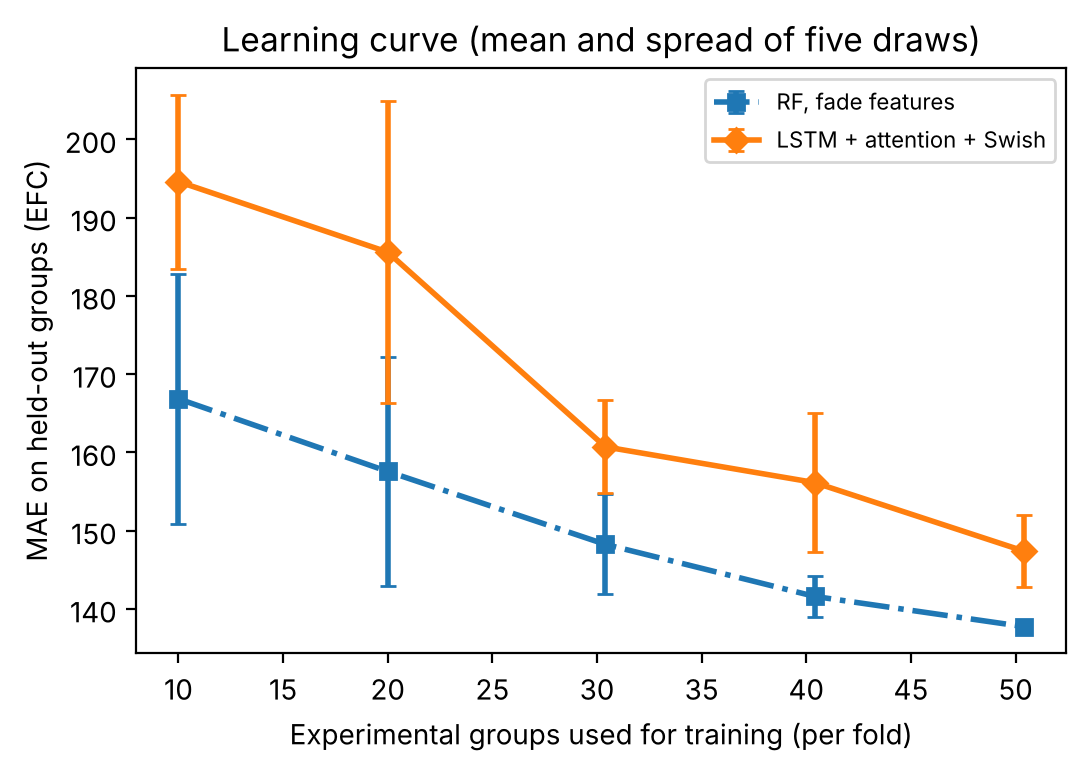

LSTM + attention + Swish            RF, fade features      
                                    mean        std              mean   std
training groups                                                            
10.0                          194.600006  11.100000             166.8  16.0
20.0                          185.600006  19.299999             157.6  14.6
30.4                          160.699997   5.900000             148.2   6.4
40.4                          156.100006   8.900000             141.6   2.7
50.4                          147.399994   4.600000             137.7   0.0

In [20]:
def rf_fade_on(train, test):
    tr = steps['cell'].isin(set(cell_ids[train])).values
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=0, n_jobs=-1)
    rf.fit(steps.loc[tr, FEATURES].values, np.log(steps.loc[tr, 'rul_efc'].values))
    return np.exp(rf.predict(steps.loc[row_index[test][M[test]], FEATURES].values))

lc_rows = []
for frac in [0.2, 0.4, 0.6, 0.8, 1.0]:
    for seed in range(N_SEEDS):
        e_lstm, e_rf, n_groups = [], [], []
        for f, (train, test) in enumerate(FOLDS):
            groups = np.unique(cell_group[train])
            keep = np.random.RandomState(1000 * seed + f).choice(groups, size=max(4, round(frac * len(groups))), replace=False)
            sub = train[np.isin(cell_group[train], keep)]
            pred, _ = train_fold(sub, test, attention=True, activation='swish', seed=seed)
            e_lstm.append(np.abs(pred - RUL[test])[M[test]])
            e_rf.append(np.abs(rf_fade_on(sub, test) - RUL[test][M[test]]))
            n_groups.append(len(keep))
        lc_rows.append({'training groups': np.mean(n_groups), 'seed': seed,
                        'LSTM + attention + Swish': np.concatenate(e_lstm).mean(),
                        'RF, fade features': np.concatenate(e_rf).mean()})
learning = pd.DataFrame(lc_rows).groupby('training groups')[['LSTM + attention + Swish', 'RF, fade features']].agg(['mean', 'std'])
learning.round(1).to_csv('figures/learning_curve.csv')

fig, ax = plt.subplots(figsize=(6, 3.8))
for name, style, marker in [('RF, fade features', '-.', 's'), ('LSTM + attention + Swish', '-', 'D')]:
    ax.errorbar(learning.index, learning[(name, 'mean')], yerr=learning[(name, 'std')], linestyle=style,
                marker=marker, lw=2, capsize=3, label=name)
ax.set_xlabel('Experimental groups used for training (per fold)')
ax.set_ylabel('MAE on held-out groups (EFC)')
ax.set_title('Learning curve (mean and spread of five draws)')
ax.legend(fontsize=8)
fig.savefig('figures/learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()
learning.round(1)

## 13. What the attention layer looks at
Attention weights of one held-out cell from the first fold. Row *k* shows how the prediction at test *k* distributes its attention over tests 0 to *k*.

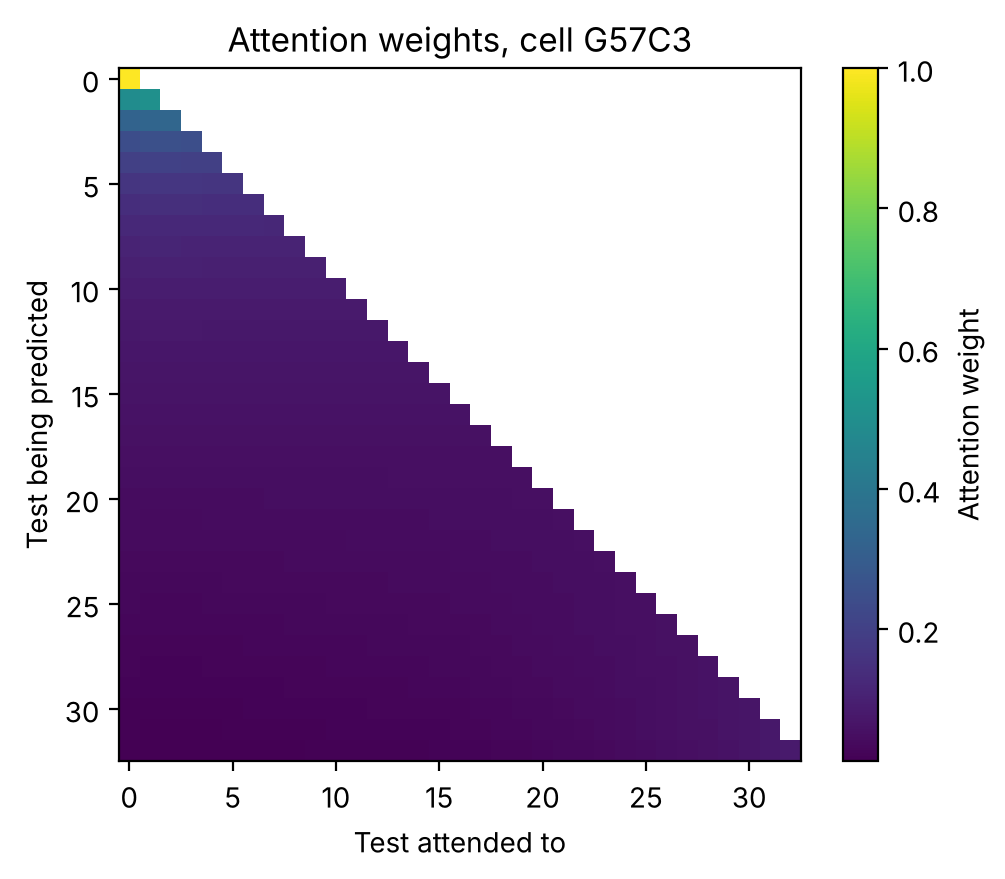

In [21]:
info = deep_info['LSTM + attention + Swish']
test_cells = info['test']
i = test_cells[np.argmax(M[test_cells].sum(axis=1))]              # the held-out cell with the longest history
t = M[i].sum()
with torch.no_grad():
    _, weights = info['model'](info['scale'](X[i:i + 1]), torch.tensor(~M[i:i + 1]), return_weights=True)
weights = np.ma.masked_where(np.triu(np.ones((t, t), dtype=bool), k=1), weights[0, :t, :t].numpy())

fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.imshow(weights, cmap='viridis', aspect='auto')
ax.set_xlabel('Test attended to'); ax.set_ylabel('Test being predicted')
ax.set_title(f'Attention weights, cell {cell_ids[i]}')
fig.colorbar(image, ax=ax, label='Attention weight')
fig.savefig('figures/attention_weights.png', dpi=150, bbox_inches='tight')
plt.show()

## 14. Predict RUL for your own cell
Enter a cell's usage conditions and its capacity history, and the model returns the predicted RUL with a 10-90% range. Five LSTM + attention + Swish models and five quantile LSTMs are trained on all cells, and their outputs are averaged.

- **Capacity** is given in % of rated capacity, one value per test, oldest first. Cells in the training data start near 113% of rated capacity.
- **EFC used** is the number of equivalent full cycles before each test, starting at 0.
- Conditions outside the range of the training data are replaced by the nearest end of the range.
- The model was trained on 250 mAh lab cells at 30 °C, so results for other batteries are only indicative.

The example uses the first six weekly tests of cell G13C4, whose true RUL at the last of them was 285 EFC.

In [22]:
final_models = [train_fold(np.arange(len(cell_ids)), np.array([0]), attention=True, activation='swish', seed=s)[1]
                for s in range(N_SEEDS)]
final_quantile_models = [train_quantile_fold(np.arange(len(cell_ids)), np.array([0]), seed=s)[1] for s in range(N_SEEDS)]

def predict_rul(capacity_pct, efc_used, c_chg, c_dis, dod):
    # Returns the predicted RUL in EFC at every test and its 10-90% range
    cap = np.asarray(capacity_pct, dtype=float) / 100 * 0.25           # % of rated -> Ah
    efc = np.asarray(efc_used, dtype=float)
    if len(cap) == 0 or len(cap) != len(efc):
        raise ValueError('Give one EFC value for every capacity value.')
    if np.any(np.diff(efc) <= 0):
        raise ValueError('EFC used must increase from one test to the next.')
    cond = []
    for value, col, label in [(c_chg, 'c_chg', 'Charge rate'), (c_dis, 'c_dis', 'Discharge rate'), (dod, 'dod', 'Depth of discharge')]:
        lo, hi = steps[col].min(), steps[col].max()
        clipped = float(np.clip(value, lo, hi))
        if abs(clipped - value) > 1e-9:
            print(f'{label} {value:.2f} is outside the data range ({lo:.2f}-{hi:.2f}); using {clipped:.2f}.')
        cond.append(clipped)
    slope = np.zeros(len(cap))
    slope[2:] = (cap[2:] - cap[:-2]) / (efc[2:] - efc[:-2])            # same definition as in section 2
    x = np.column_stack([cap, efc, cap[0] - cap, slope] + [np.full(len(cap), c) for c in cond])[None].astype(np.float32)
    no_padding = torch.zeros(1, len(cap), dtype=torch.bool)
    with torch.no_grad():
        preds = np.array([np.exp(m['model'](m['scale'](x), no_padding).numpy()[0]) for m in final_models])
        ranges = np.array([np.exp(np.sort(m['model'](m['scale'](x), no_padding).numpy()[0], axis=-1))
                           for m in final_quantile_models]).mean(axis=0)
    return preds.mean(axis=0), ranges[:, 0], ranges[:, 2]

Predicted RUL after 6 tests: 364 EFC (10-90% range: 242-512 EFC)
At 0.78 EFC per day: about 15.3 months (range 10.2-21.6)


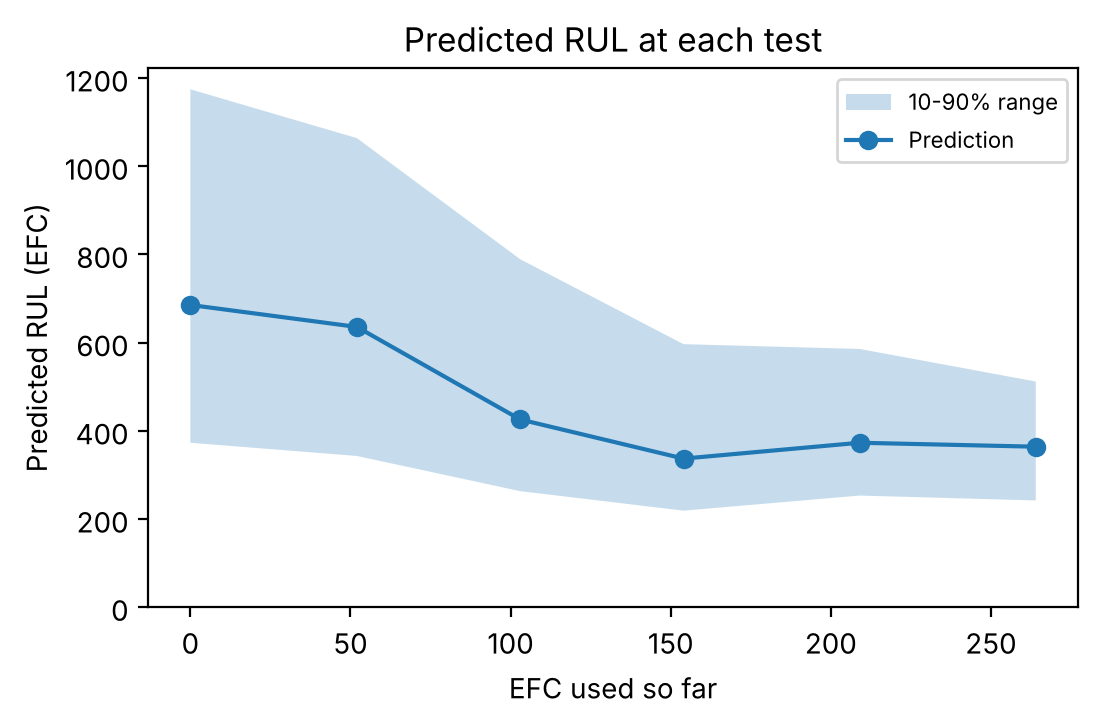

In [23]:
def show_prediction(c_chg, c_dis, dod_pct, capacity_pct, efc_used, efc_per_day):
    # capacity_pct and efc_used are comma-separated text, e.g. "113.7, 100.8, 97.7"
    try:
        capacity = [float(v) for v in capacity_pct.split(',') if v.strip()]
        efc = [float(v) for v in efc_used.split(',') if v.strip()]
        mean, low, high = predict_rul(capacity, efc, c_chg, c_dis, dod_pct / 100)
    except ValueError as problem:
        print('Check the inputs:', problem)
        return
    print(f'Predicted RUL after {len(efc)} tests: {mean[-1]:.0f} EFC (10-90% range: {low[-1]:.0f}-{high[-1]:.0f} EFC)')
    if efc_per_day > 0:
        to_months = lambda v: v / efc_per_day / 30.4
        print(f'At {efc_per_day} EFC per day: about {to_months(mean[-1]):.1f} months '
              f'(range {to_months(low[-1]):.1f}-{to_months(high[-1]):.1f})')
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.fill_between(efc, low, high, alpha=0.25, label='10-90% range')
    ax.plot(efc, mean, '-o', label='Prediction')
    ax.legend(fontsize=8)
    ax.set_xlabel('EFC used so far'); ax.set_ylabel('Predicted RUL (EFC)')
    ax.set_title('Predicted RUL at each test')
    ax.set_ylim(bottom=0)
    plt.show()

# Example: the first six weekly tests of cell G13C4
show_prediction(c_chg=3.0, c_dis=0.5, dod_pct=47,
                capacity_pct='113.7, 100.8, 97.7, 96.6, 96.3, 95.5',
                efc_used='0, 52, 103, 154, 209, 264', efc_per_day=0.78)

### Interactive form
Run the cell below, change the values in the boxes, and press **Predict**. The result appears under the button.

In [24]:
import ipywidgets as widgets
from IPython.display import display, clear_output

wide = {'description_width': '170px'}
box = widgets.Layout(width='520px')
w_chg = widgets.BoundedFloatText(value=3.0, min=0.1, max=5.0, step=0.1, description='Charge rate (C)', style=wide, layout=box)
w_dis = widgets.BoundedFloatText(value=0.5, min=0.1, max=5.0, step=0.1, description='Discharge rate (C)', style=wide, layout=box)
w_dod = widgets.IntSlider(value=47, min=4, max=100, description='Depth of discharge (%)', style=wide, layout=box)
w_cap = widgets.Text(value='113.7, 100.8, 97.7, 96.6, 96.3, 95.5', description='Capacity (% of rated)', style=wide, layout=box)
w_efc = widgets.Text(value='0, 52, 103, 154, 209, 264', description='EFC used at each test', style=wide, layout=box)
w_day = widgets.BoundedFloatText(value=0.78, min=0.0, max=10.0, step=0.01, description='EFC per day (0 to skip)', style=wide, layout=box)
button = widgets.Button(description='Predict', button_style='primary')
result = widgets.Output()

def on_click(_):
    with result:
        clear_output(wait=True)
        show_prediction(w_chg.value, w_dis.value, w_dod.value, w_cap.value, w_efc.value, w_day.value)

button.on_click(on_click)
display(widgets.VBox([w_chg, w_dis, w_dod, w_cap, w_efc, w_day, button, result]))